# Notebook de documentacion, tratamiento datos y entrenamiento


## Equipo
- Alumno 1 : Damián Grimaldi
- Alumno 2 : Nicolas Duclos

# **Descripción del dataset**

El dataset utilizado, es de proveniente de kaggle, que contiene imagenes de `105` famosos distintos, y con un total de `17534` fotos distribuidas. Cuyo formato de las imagenes son de `.jpg`.

Se decidio utilizar esta dataset, ya que contiene una gran amplia cantidad de imagenes de distintos famosos, ya que este mismo, contiene entre 86 a 237 imagenes por cada famoso, lo que es ideal para entrenar nuestro modelo.

Una limitación de este dataset, es que es un dataset desbalanceado, ya que este mismo, no cuenta con la misma cantidad de imagenes por famoso.

# **Objetivo de la sección**

El objetivo es preparar al dataset en condiciones para realizar un entrenamiento para reconocer rostros.

# **Librerias**

In [1]:
import kagglehub
import os

import torch
import torch.nn.functional as F

from sklearn.metrics.pairwise import cosine_similarity

import cv2
import numpy as np
import matplotlib.pyplot as plt

from itertools import combinations

from PIL import Image
from facenet_pytorch import MTCNN, InceptionResnetV1
from facenet_pytorch.models.mtcnn import extract_face

from sklearn.manifold import TSNE

from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | Dispositivo: {device}")

c:\Users\grima\Desktop\UNR\TUIA\5° cuatri\COMPUTER VISION\PRACTICA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128 | Dispositivo: cuda


Importamos las librerias necesarias.

# **Descarga del dataset**

In [2]:
# Download latest version
path = kagglehub.dataset_download(
    "hereisburak/pins-face-recognition",
)

print("Path to dataset files:", path)

Path to dataset files: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1


Descargamos el dataset de kaggle

# **EDA**

In [3]:
def grafico_barra(x, y, titulo, xlabel, y_label, yticks = 25):

    plt.figure(figsize=(30, 10))

    plt.bar(x, y, width=0.5)

    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(y_label)

    plt.yticks(np.arange(0, max(y) + yticks, yticks))

    plt.show()

Creamos una funcion general para los graficos de barras.

## **Balanceo del dataset**

In [4]:
dataset_dir = os.path.join(path, "105_classes_pins_dataset")

extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}
total_imagenes = 0

persona_cantidad = {}
persona_imagenes = {}

for carpeta, _, archivos in os.walk(dataset_dir):
    imagenes = [
        archivo for archivo in archivos
        if os.path.splitext(archivo)[1].lower() in extensiones
    ]

    
    if imagenes:
        persona_imagenes[os.path.basename(carpeta)] = imagenes
        persona_cantidad[os.path.basename(carpeta)] = len(imagenes)
        print(f"{os.path.basename(carpeta)}: {len(imagenes)} imágenes")
        total_imagenes += len(imagenes)

print(f"\nTotal de imágenes: {total_imagenes}")

pins_Adriana Lima: 213 imágenes
pins_Alex Lawther: 152 imágenes
pins_Alexandra Daddario: 225 imágenes
pins_Alvaro Morte: 139 imágenes
pins_alycia dabnem carey: 211 imágenes
pins_Amanda Crew: 117 imágenes
pins_amber heard: 218 imágenes
pins_Andy Samberg: 196 imágenes
pins_Anne Hathaway: 203 imágenes
pins_Anthony Mackie: 124 imágenes
pins_Avril Lavigne: 162 imágenes
pins_barack obama: 119 imágenes
pins_barbara palvin: 197 imágenes
pins_Ben Affleck: 126 imágenes
pins_Bill Gates: 122 imágenes
pins_Bobby Morley: 138 imágenes
pins_Brenton Thwaites: 209 imágenes
pins_Brian J. Smith: 102 imágenes
pins_Brie Larson: 169 imágenes
pins_camila mendes: 162 imágenes
pins_Chris Evans: 166 imágenes
pins_Chris Hemsworth: 159 imágenes
pins_Chris Pratt: 176 imágenes
pins_Christian Bale: 154 imágenes
pins_Cristiano Ronaldo: 98 imágenes
pins_Danielle Panabaker: 181 imágenes
pins_Dominic Purcell: 146 imágenes
pins_Dwayne Johnson: 141 imágenes
pins_Eliza Taylor: 162 imágenes
pins_Elizabeth Lail: 158 imágenes


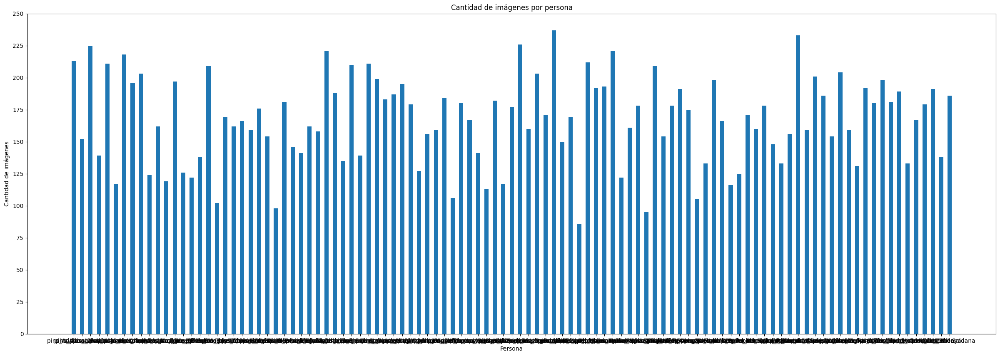

In [5]:
grafico_barra(
    list(persona_cantidad.keys()),
    list(persona_cantidad.values()),
    "Cantidad de imágenes por persona",
    "Persona",
    "Cantidad de imágenes"
)

Se puede observar que el dataset está desbalanceado, ya que en el, ronda entre 86 imágenes pertenecientes a Lionel Messi, y 237 imágenes pertenecientes a Leonardo DiCaprio. Antes de realizar alguna modificación para balancear el dataset, hay que verificar si dichas imágenes cumplen cierto formato, y a su vez, verificar si todas son óptimas a utilizar, por lo que primero se va a realizar una limpieza de las imágenes.

In [6]:
persona_cantidad_sorted = dict(sorted(persona_cantidad.items(), key=lambda item: item[1], reverse=True))
persona_cantidad_sorted

{'pins_Leonardo DiCaprio': 237,
 'pins_Robert Downey Jr': 233,
 'pins_Katherine Langford': 226,
 'pins_Alexandra Daddario': 225,
 'pins_elizabeth olsen': 221,
 'pins_margot robbie': 221,
 'pins_amber heard': 218,
 'pins_Adriana Lima': 213,
 'pins_Logan Lerman': 212,
 'pins_alycia dabnem carey': 211,
 'pins_Emma Watson': 211,
 'pins_Emilia Clarke': 210,
 'pins_Brenton Thwaites': 209,
 'pins_Megan Fox': 209,
 'pins_Sophie Turner': 204,
 'pins_Anne Hathaway': 203,
 'pins_kiernen shipka': 203,
 'pins_scarlett johansson': 201,
 'pins_gal gadot': 199,
 'pins_Natalie Dormer': 198,
 'pins_Tom Hardy': 198,
 'pins_barbara palvin': 197,
 'pins_Andy Samberg': 196,
 'pins_Henry Cavil': 195,
 'pins_Maisie Williams': 193,
 'pins_Madelaine Petsch': 192,
 'pins_Tom Cruise': 192,
 'pins_Millie Bobby Brown': 191,
 'pins_Zac Efron': 191,
 'pins_Tom Holland': 189,
 'pins_ellen page': 188,
 'pins_Gwyneth Paltrow': 187,
 'pins_Selena Gomez': 186,
 'pins_Zoe Saldana': 186,
 'pins_Jason Momoa': 184,
 'pins_gra

In [7]:
minimo_imagenes = min(persona_cantidad_sorted.values())
maximo_imagenes = max(persona_cantidad_sorted.values())

media_imagenes = sum(persona_cantidad_sorted.values()) / len(persona_cantidad_sorted)

mediana_imagenes = np.median(list(persona_cantidad_sorted.values()))

print(f"\nMínimo de imágenes por persona: {minimo_imagenes}")
print(f"Máximo de imágenes por persona: {maximo_imagenes}")
print(f"Media de imágenes por persona: {media_imagenes}")
print(f"Mediana de imágenes por persona: {mediana_imagenes}")


Mínimo de imágenes por persona: 86
Máximo de imágenes por persona: 237
Media de imágenes por persona: 166.9904761904762
Mediana de imágenes por persona: 169.0


El dataset cuenta con un mínimo de 86 imágenes, con un máximo de 237 imágenes para un famoso. Con un promedio de 167 imágenes, y con una mediana de 169 imágenes.

In [8]:
q_25 = np.percentile(list(persona_cantidad_sorted.values()), 25)
q_75 = np.percentile(list(persona_cantidad_sorted.values()), 75)

print(f"Cuartil 25: {q_25}")
print(f"Cuartil 75: {q_75}")

print(f"Rango intercuartílico: {q_75 - q_25}")

riq_inferior = q_25 - 1.5 * (q_75 - q_25)
riq_superior = q_75 + 1.5 * (q_75 - q_25)

print(f"Rango inferior: {riq_inferior}")
print(f"Rango superior: {riq_superior}")

Cuartil 25: 141.0
Cuartil 75: 192.0
Rango intercuartílico: 51.0
Rango inferior: 64.5
Rango superior: 268.5


Tras realizar el rango intercuartil, no se encontró que ninguna imagen, se puede considerar fuera de rango

## **Validación de tamaño minimo**

In [9]:
# tamaño minimo 112x112

personas_que_no_cumplen = {}
personas_cumplen_ruta = {}

for persona, imagenes in persona_imagenes.items():
    for imagen in imagenes:
        ruta_imagen = os.path.join(dataset_dir, persona, imagen)
        img = cv2.imread(ruta_imagen)
        if img is None:
            print(f"No se pudo leer la imagen: {ruta_imagen}")
            continue

        alto, ancho, canales = img.shape

        if ancho < 112 or alto < 112:
            if persona not in personas_que_no_cumplen:
                personas_que_no_cumplen[persona] = []
            personas_que_no_cumplen[persona].append(imagen)

        else:
            if persona not in personas_cumplen_ruta:
                personas_cumplen_ruta[persona] = []
            personas_cumplen_ruta[persona].append(imagen)

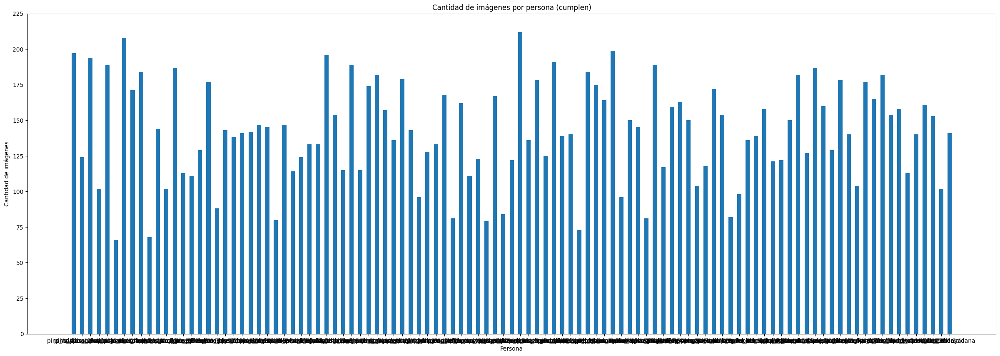

In [10]:
personas_no_cumplen = {persona: len(imagenes) for persona, imagenes in personas_que_no_cumplen.items()}
personas_cumplen = {persona: persona_cantidad[persona] - len(imagenes) for persona, imagenes in personas_que_no_cumplen.items()}

grafico_barra(
    list(personas_cumplen.keys()),
    list(personas_cumplen.values()),
    "Cantidad de imágenes por persona (cumplen)",
    "Persona",
    "Cantidad de imágenes"
)

In [11]:
maximo = personas_no_cumplen[max(personas_no_cumplen, key=personas_no_cumplen.get)]
minimo = personas_no_cumplen[min(personas_no_cumplen, key=personas_no_cumplen.get)]

print("Maximas personas que no cumplen con el tamaño mínimo de 112x112:", maximo)
print("Minimo de imágenes que no cumplen con el tamaño mínimo de 112x112:", minimo)

minimo_cumplen = personas_cumplen[min(personas_cumplen, key=personas_cumplen.get)]
maximo_cumplen = personas_cumplen[max(personas_cumplen, key=personas_cumplen.get)]
print("Minimo de imágenes que cumplen con el tamaño mínimo de 112x112:", minimo_cumplen)
print("Maximo de imágenes que cumplen con el tamaño mínimo de 112x112:", maximo_cumplen)

Maximas personas que no cumplen con el tamaño mínimo de 112x112: 56
Minimo de imágenes que no cumplen con el tamaño mínimo de 112x112: 1
Minimo de imágenes que cumplen con el tamaño mínimo de 112x112: 66
Maximo de imágenes que cumplen con el tamaño mínimo de 112x112: 212


Luego de verificar y eliminar las fotos que no cumplen con el formato mínimo, se eliminaron, pasando un nuevo rango, de 66 a 212 imágenes, aun asi, esto sigue siendo desbalanceado.

In [12]:
personas_cumplen_sorted = dict(sorted(personas_cumplen.items(), key=lambda item: item[1], reverse=True))
personas_cumplen_sorted

{'pins_Katherine Langford': 212,
 'pins_amber heard': 208,
 'pins_margot robbie': 199,
 'pins_Adriana Lima': 197,
 'pins_elizabeth olsen': 196,
 'pins_Alexandra Daddario': 194,
 'pins_Leonardo DiCaprio': 191,
 'pins_alycia dabnem carey': 189,
 'pins_Emilia Clarke': 189,
 'pins_Megan Fox': 189,
 'pins_barbara palvin': 187,
 'pins_scarlett johansson': 187,
 'pins_Anne Hathaway': 184,
 'pins_Logan Lerman': 184,
 'pins_gal gadot': 182,
 'pins_Robert Downey Jr': 182,
 'pins_Tom Hardy': 182,
 'pins_Henry Cavil': 179,
 'pins_kiernen shipka': 178,
 'pins_Sophie Turner': 178,
 'pins_Brenton Thwaites': 177,
 'pins_Tom Cruise': 177,
 'pins_Madelaine Petsch': 175,
 'pins_Emma Watson': 174,
 'pins_Natalie Dormer': 172,
 'pins_Andy Samberg': 171,
 'pins_Jason Momoa': 168,
 'pins_Johnny Depp': 167,
 'pins_tom ellis': 165,
 'pins_Maisie Williams': 164,
 'pins_Millie Bobby Brown': 163,
 'pins_Jennifer Lawrence': 162,
 'pins_Wentworth Miller': 161,
 'pins_Selena Gomez': 160,
 'pins_Miley Cyrus': 159,
 '

## **Canales y formato**

In [13]:
# Validación de canales, extensiones e imágenes corruptas

canales_por_imagen = {}
extensiones_encontradas = {}
imagenes_corruptas = {}
resumen_canales = {}
resumen_extensiones = {}

for persona, imagenes in personas_cumplen_ruta.items():
    resumen_canales[persona] = {
        "RGB o BGR": 0,
        "Escala de grises": 0,
        "RGBA": 0,
        "Otros": 0,
        "Corruptas": 0
    }
    resumen_extensiones[persona] = {}
    imagenes_corruptas[persona] = []

    for nombre_imagen in imagenes:
        ruta = os.path.join(dataset_dir, persona, nombre_imagen)
        extension = os.path.splitext(nombre_imagen)[1].lower()

        extensiones_encontradas[nombre_imagen] = extension
        resumen_extensiones[persona][extension] = (
            resumen_extensiones[persona].get(extension, 0) + 1
        )

        imagen = cv2.imread(ruta, cv2.IMREAD_UNCHANGED)

        # La imagen no pudo abrirse o está corrupta
        if imagen is None:
            canales_por_imagen[nombre_imagen] = "Corrupta o ilegible"
            imagenes_corruptas[persona].append(nombre_imagen)
            resumen_canales[persona]["Corruptas"] += 1
            continue

        if len(imagen.shape) == 2:
            tipo_canal = "Escala de grises"
        elif imagen.shape[2] == 3:
            tipo_canal = "RGB o BGR"
        elif imagen.shape[2] == 4:
            tipo_canal = "RGBA"
        else:
            tipo_canal = "Otros"

        canales_por_imagen[nombre_imagen] = tipo_canal
        resumen_canales[persona][tipo_canal] += 1

# Resumen general
total_por_canal = {
    "RGB o BGR": 0,
    "Escala de grises": 0,
    "RGBA": 0,
    "Otros": 0,
    "Corruptas": 0
}

for resumen in resumen_canales.values():
    for tipo, cantidad in resumen.items():
        total_por_canal[tipo] += cantidad

print("Resumen de canales:")
for tipo, cantidad in total_por_canal.items():
    print(f"- {tipo}: {cantidad}")

print("\nExtensiones encontradas:")
extensiones_totales = {}

for extensiones in resumen_extensiones.values():
    for extension, cantidad in extensiones.items():
        extensiones_totales[extension] = (
            extensiones_totales.get(extension, 0) + cantidad
        )

for extension, cantidad in sorted(extensiones_totales.items()):
    print(f"- {extension}: {cantidad}")

print("\nImágenes corruptas o ilegibles:")
cantidad_corruptas = sum(len(imagenes) for imagenes in imagenes_corruptas.values())
print(f"Total: {cantidad_corruptas}")

for persona, imagenes in imagenes_corruptas.items():
    if imagenes:
        print(f"\n{persona}:")
        for imagen in imagenes:
            print(f"- {imagen}")

Resumen de canales:
- RGB o BGR: 14908
- Escala de grises: 0
- RGBA: 0
- Otros: 0
- Corruptas: 0

Extensiones encontradas:
- .jpg: 14908

Imágenes corruptas o ilegibles:
Total: 0


Luego de eliminar las imágenes que no cumplen con el formato mínimo, nos quedamos con 14908 imágenes, de las cuales, todas y cada una, son de la escala de `RGB` o en el formato de `BGR`, y ninguna de estas imágenes, se encuentra en el formato de `.jpg` y que ninguna de ellas se logra observar que son corruptas.

## **Muestra visual**




In [14]:
rutas_muestra = personas_cumplen_ruta

muestras_visual = {}

for persona, imagenes in rutas_muestra.items():
    imagenes_validas = []

    for nombre_imagen in imagenes:
        ruta_imagen = os.path.join(dataset_dir, persona, nombre_imagen)
        imagen = cv2.imread(ruta_imagen)

        if imagen is None:
            continue

        gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
        nitidez = cv2.Laplacian(gris, cv2.CV_64F).var()

        imagenes_validas.append({
            "nombre": nombre_imagen,
            "ruta": ruta_imagen,
            "nitidez": nitidez
        })

    if imagenes_validas:
        ordenadas = sorted(imagenes_validas, key=lambda x: x["nitidez"])

        indices = [
            0,
            len(ordenadas) // 2,
            len(ordenadas) - 1
        ]

        muestras_visual[persona] = [ordenadas[i] for i in indices]

fig, axes = plt.subplots(
    len(muestras_visual),
    3,
    figsize=(10, 2.8 * len(muestras_visual))
)

if len(muestras_visual) == 1:
    axes = np.expand_dims(axes, axis=0)

for fila, (persona, muestras) in enumerate(muestras_visual.items()):
    for columna, muestra in enumerate(muestras):
        imagen = cv2.imread(muestra["ruta"])
        imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

        axes[fila, columna].imshow(imagen)
        axes[fila, columna].set_title(
            f"{['Difícil', 'Representativa', 'Nítida'][columna]}\n"
            f"Nitidez: {muestra['nitidez']:.2f}",
            fontsize=8
        )
        axes[fila, columna].axis("off")

    axes[fila, 0].set_ylabel(
        persona,
        fontsize=9,
        fontweight="bold",
        rotation=0,
        labelpad=65,
        va="center"
    )

plt.suptitle(
    "Muestra visual por identidad incluyendo casos difíciles",
    fontsize=16,
    y=1.0
)

plt.tight_layout()
plt.show()

Aquí podemos observar que a pesar de que haya una gran variación en la nitidez de la imágenes y algunas se pueden considerar como poco útiles para los posteriores entrenamientos, no podemos hacer esa limpieza basándose únicamente en el valor de nitidez.

## **Variaciones**

### **Brillo y contraste**

In [15]:
brillo_promedio_por_persona = {}
contraste_promedio_por_persona = {}

for persona, imagenes in personas_cumplen_ruta.items():
    for imagen in imagenes:
        ruta_imagen = os.path.join(dataset_dir, persona, imagen)
        img = cv2.imread(ruta_imagen)
        if img is None:
            print(f"No se pudo leer la imagen: {ruta_imagen}")
            continue

        img_gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        brillo = np.mean(img_gris)
        contraste = np.std(img_gris)

        if persona not in brillo_promedio_por_persona:
            brillo_promedio_por_persona[persona] = []
            contraste_promedio_por_persona[persona] = []

        brillo_promedio_por_persona[persona].append(brillo)
        contraste_promedio_por_persona[persona].append(contraste)

print("Brillo promedio por persona:")
for persona, brillos in brillo_promedio_por_persona.items():
    promedio_brillo = np.mean(brillos)
    print(f"- {persona}: {promedio_brillo:.2f}")

print("Contraste promedio por persona:")
for persona, contrastes in contraste_promedio_por_persona.items():
    promedio_contraste = np.mean(contrastes)
    print(f"- {persona}: {promedio_contraste:.2f}")

Brillo promedio por persona:
- pins_Adriana Lima: 107.85
- pins_Alex Lawther: 97.67
- pins_Alexandra Daddario: 108.26
- pins_Alvaro Morte: 93.76
- pins_alycia dabnem carey: 115.01
- pins_Amanda Crew: 108.38
- pins_amber heard: 130.99
- pins_Andy Samberg: 114.13
- pins_Anne Hathaway: 113.62
- pins_Anthony Mackie: 96.08
- pins_Avril Lavigne: 136.49
- pins_barack obama: 110.91
- pins_barbara palvin: 112.92
- pins_Ben Affleck: 104.64
- pins_Bill Gates: 115.68
- pins_Bobby Morley: 90.41
- pins_Brenton Thwaites: 113.07
- pins_Brian J. Smith: 97.47
- pins_Brie Larson: 123.95
- pins_camila mendes: 99.85
- pins_Chris Evans: 113.38
- pins_Chris Hemsworth: 115.91
- pins_Chris Pratt: 116.23
- pins_Christian Bale: 110.14
- pins_Cristiano Ronaldo: 118.55
- pins_Danielle Panabaker: 117.09
- pins_Dominic Purcell: 113.93
- pins_Dwayne Johnson: 122.43
- pins_Eliza Taylor: 135.41
- pins_Elizabeth Lail: 124.60
- pins_elizabeth olsen: 119.99
- pins_ellen page: 106.53
- pins_elon musk: 114.26
- pins_Emilia 

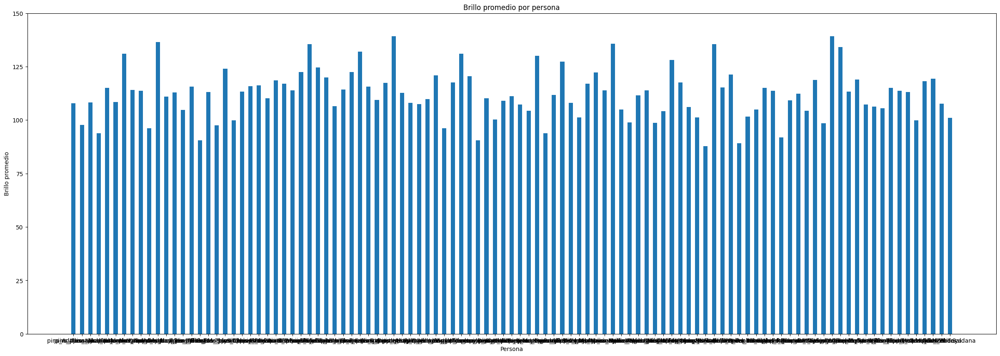

In [16]:
grafico_barra(
    list(brillo_promedio_por_persona.keys()),
    [np.mean(brillos) for brillos in brillo_promedio_por_persona.values()],
    "Brillo promedio por persona",
    "Persona",
    "Brillo promedio"
)

Brillo observado (mínimo, Q1, mediana, Q3, máximo): 14.0, 91.7, 112.1, 133.9, 221.8
Se muestran 25 imagenes ordenadas desde las mas oscuras hasta las mas claras. Evalúa visualmente si cada una conserva detalle facial; estos valores por sí solos no determinan un umbral de calidad.


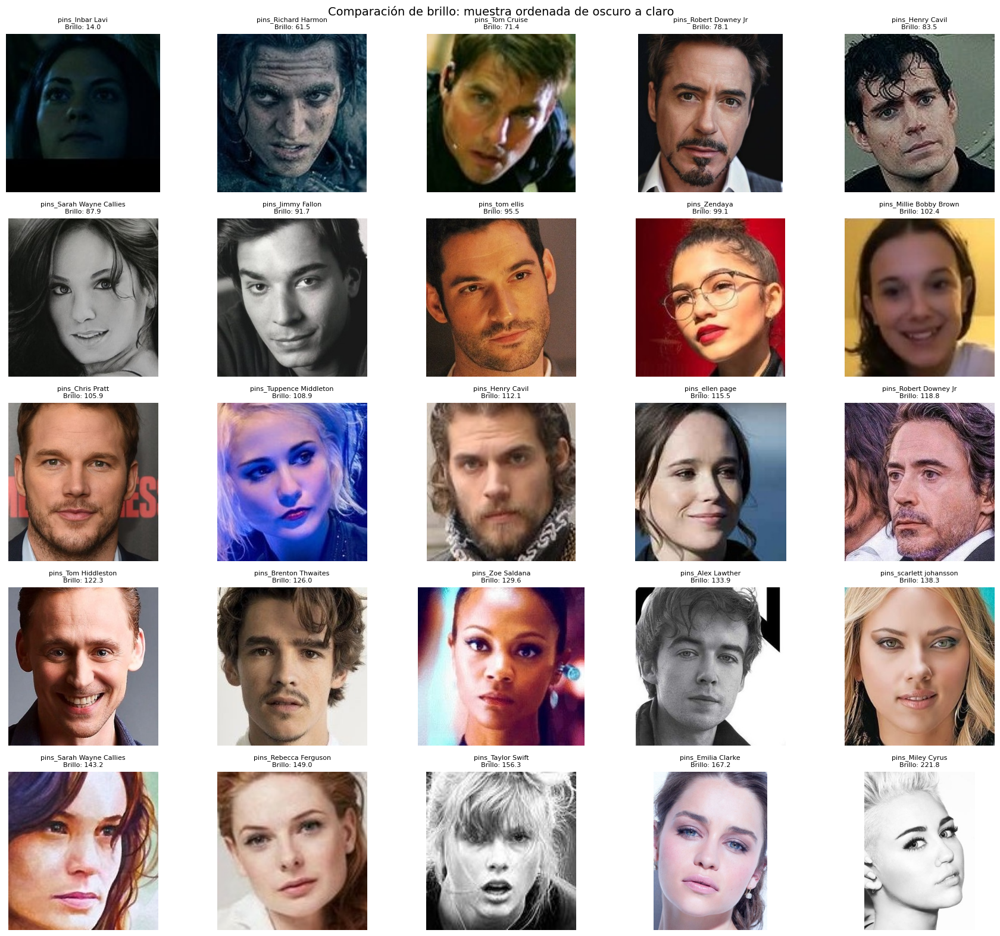

In [17]:
# Comparar imagenes con distintos niveles de brillo
muestras_brillo = []

for persona, imagenes in personas_cumplen_ruta.items():
    for nombre_imagen in imagenes:
        ruta_imagen = os.path.join(dataset_dir, persona, nombre_imagen)
        imagen = cv2.imread(ruta_imagen)
        if imagen is None:
            print(f"No se pudo leer la imagen: {ruta_imagen}")
            continue

        gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
        muestras_brillo.append({
            "persona": persona,
            "nombre": nombre_imagen,
            "ruta": ruta_imagen,
            "brillo": float(np.mean(gris))
        })

if not muestras_brillo:
    raise ValueError("No se encontraron imagenes validas para comparar el brillo.")

muestras_brillo.sort(key=lambda muestra: muestra["brillo"])
indices_muestra = np.linspace(
    0,
    len(muestras_brillo) - 1,
    min(25, len(muestras_brillo)),
    dtype=int
)
imagenes_muestra = [muestras_brillo[indice] for indice in indices_muestra]

percentiles_brillo = np.percentile(
    [muestra["brillo"] for muestra in muestras_brillo],
    [0, 25, 50, 75, 100]
)
print(
    "Brillo observado (mínimo, Q1, mediana, Q3, máximo): "
    + ", ".join(f"{valor:.1f}" for valor in percentiles_brillo)
)
print(
    f"Se muestran {len(imagenes_muestra)} imagenes ordenadas desde las mas oscuras "
    "hasta las mas claras. Evalúa visualmente si cada una conserva detalle facial; "
    "estos valores por sí solos no determinan un umbral de calidad."
)

fig, axes = plt.subplots(5, 5, figsize=(18, 16), squeeze=False)
for eje in axes.flat:
    eje.axis("off")

for eje, muestra in zip(axes.flat, imagenes_muestra):
    imagen = cv2.imread(muestra["ruta"])
    if imagen is None:
        raise FileNotFoundError(f"No se pudo leer la imagen: {muestra['ruta']}")

    eje.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    eje.set_title(
        f"{muestra['persona']}\nBrillo: {muestra['brillo']:.1f}",
        fontsize=8
    )
    eje.axis("off")

fig.suptitle(
    "Comparación de brillo: muestra ordenada de oscuro a claro",
    fontsize=14
)
plt.tight_layout()
plt.show()

Aquí podemos observar que sería factible poner un umbral mínimo de brillo debido a que la primera imagen se podría considerar demasiado oscura y que no contiene información útil para los entrenamientos.

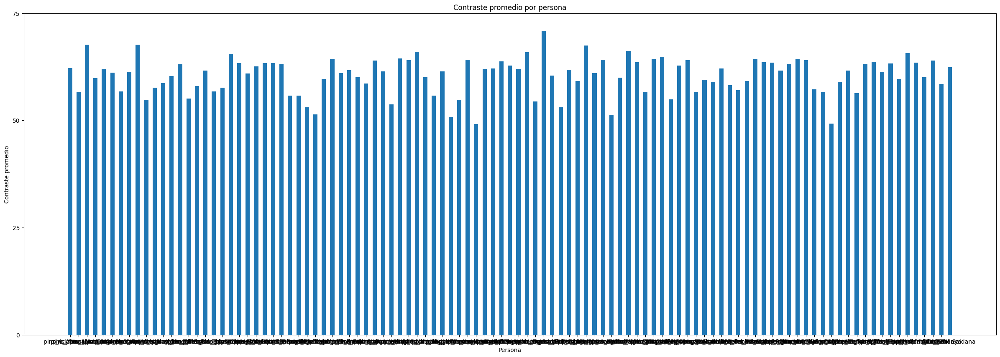

In [18]:
grafico_barra(
    list(contraste_promedio_por_persona.keys()),
    [np.mean(contrastes) for contrastes in contraste_promedio_por_persona.values()],
    "Contraste promedio por persona",
    "Persona",
    "Contraste promedio"
)

# **Limpieza de imagenes**

## **Cantidad de rostros por imagen**

In [19]:
detector = MTCNN(
    image_size=112,
    margin=0,
    keep_all=True,
    device=device,
)
print(f"MTCNN inicializado en {device}")

MTCNN inicializado en cuda


In [20]:
personas_cumplen_ruta_con_una_imagen = {}
personas_que_tienen_mas_de_un_rostro = {}
personas_sin_rostro_detectado = {}

for persona, imagenes in personas_cumplen_ruta.items():

    for img in imagenes:

        ruta_imagen = os.path.join(dataset_dir, persona, img)

        imagen = cv2.imread(ruta_imagen)

        # Evitar errores si la imagen no se puede cargar
        if imagen is None:
            print(f"No se pudo cargar: {ruta_imagen}")
            continue

        imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
        pil = Image.fromarray(imagen)

        boxes, probs, landmarks = detector.detect(pil, landmarks=True)

        # Clasificar según la cantidad de rostros detectados
        if boxes is None or len(boxes) == 0:

            personas_sin_rostro_detectado.setdefault(persona, []).append(
                (img, "No se detectaron rostros en la imagen")
            )

        elif len(boxes) > 1:

            personas_que_tienen_mas_de_un_rostro.setdefault(persona, []).append(
                (img, f"Se detectaron {len(boxes)} rostros en la imagen")
            )

        else:

            personas_cumplen_ruta_con_una_imagen.setdefault(persona, []).append(img)

Total de imágenes con múltiples rostros detectados: 166
Total de personas con múltiples rostros detectados: 77


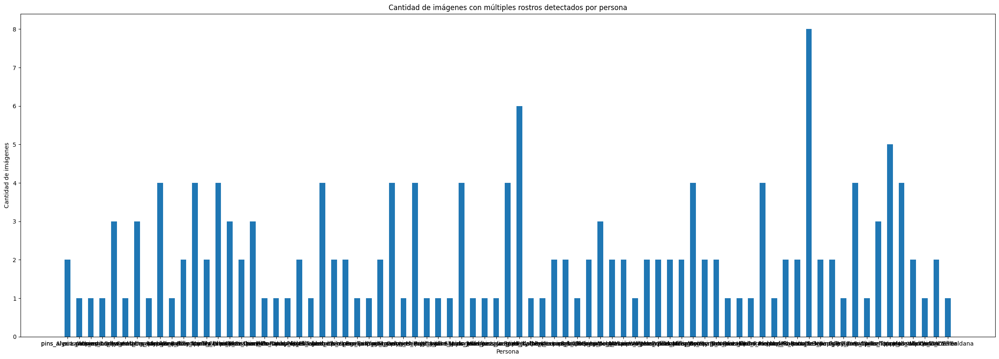

In [21]:
total_imagenes_con_mas_de_un_rostro = sum(
    len(imagenes) for imagenes in personas_que_tienen_mas_de_un_rostro.values()
)
print(f"Total de imágenes con múltiples rostros detectados: {total_imagenes_con_mas_de_un_rostro}")

total_personas_con_mas_de_un_rostro = len(personas_que_tienen_mas_de_un_rostro)
print(f"Total de personas con múltiples rostros detectados: {total_personas_con_mas_de_un_rostro}")

grafico_barra(
    list(personas_que_tienen_mas_de_un_rostro.keys()),
    [len(imagenes) for imagenes in personas_que_tienen_mas_de_un_rostro.values()],
    "Cantidad de imágenes con múltiples rostros detectados por persona",
    "Persona",
    "Cantidad de imágenes",
    1
)

Total de imágenes sin rostros detectados: 44
Total de personas sin rostros detectados: 31


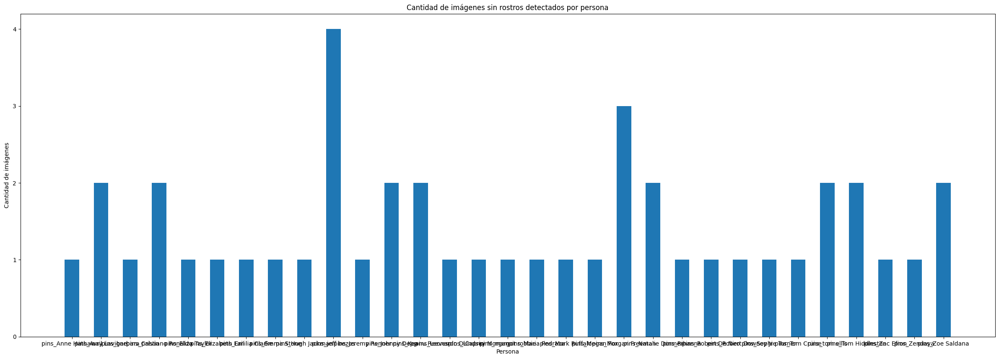

In [22]:
total_imagenes_sin_rostro = sum(
    len(imagenes) for imagenes in personas_sin_rostro_detectado.values()
)
print(f"Total de imágenes sin rostros detectados: {total_imagenes_sin_rostro}")

total_personas_sin_rostro = len(personas_sin_rostro_detectado)
print(f"Total de personas sin rostros detectados: {total_personas_sin_rostro}")

grafico_barra(
    list(personas_sin_rostro_detectado.keys()),
    [len(imagenes) for imagenes in personas_sin_rostro_detectado.values()],
    "Cantidad de imágenes sin rostros detectados por persona",
    "Persona",
    "Cantidad de imágenes",
    1
)

In [23]:
total_imagenes_sin_rostro + total_imagenes_con_mas_de_un_rostro

210

Tras evaluar todas las imagenes y observar cuales regristra más de un rostro, encontramos que 77 de las 107 famosos, contienen al menos más de un rostro encontrado, por lo que hemos decidido quedarnos sin ellas, no solamanete encontramos con famosos con más de un rostro, tambien encontramos que 33 de ellos, no se encontraron ninguno, por lo que tras esta eliminación, hemos eliminados un total de 210 imagenes entre ambos.

## **Resolución minima de rostros**

Persona: pins_Adriana Lima, Probabilidad: 0.9919, BBox: (19, 0, 550, 668), Ancho: 531
Persona: pins_Alex Lawther, Probabilidad: 1.0000, BBox: (0, 10, 217, 320), Ancho: 217
Persona: pins_Alexandra Daddario, Probabilidad: 0.9997, BBox: (0, 3, 134, 179), Ancho: 134
Persona: pins_Alvaro Morte, Probabilidad: 1.0000, BBox: (21, 20, 114, 138), Ancho: 93
Persona: pins_alycia dabnem carey, Probabilidad: 0.9996, BBox: (40, 14, 188, 236), Ancho: 148
Persona: pins_Amanda Crew, Probabilidad: 0.9995, BBox: (55, 33, 267, 324), Ancho: 212
Persona: pins_amber heard, Probabilidad: 1.0000, BBox: (48, 32, 370, 496), Ancho: 322
Persona: pins_Andy Samberg, Probabilidad: 1.0000, BBox: (22, 7, 135, 160), Ancho: 113
Persona: pins_Anne Hathaway, Probabilidad: 1.0000, BBox: (34, 3, 176, 211), Ancho: 142
Persona: pins_Anthony Mackie, Probabilidad: 1.0000, BBox: (30, 19, 103, 117), Ancho: 73


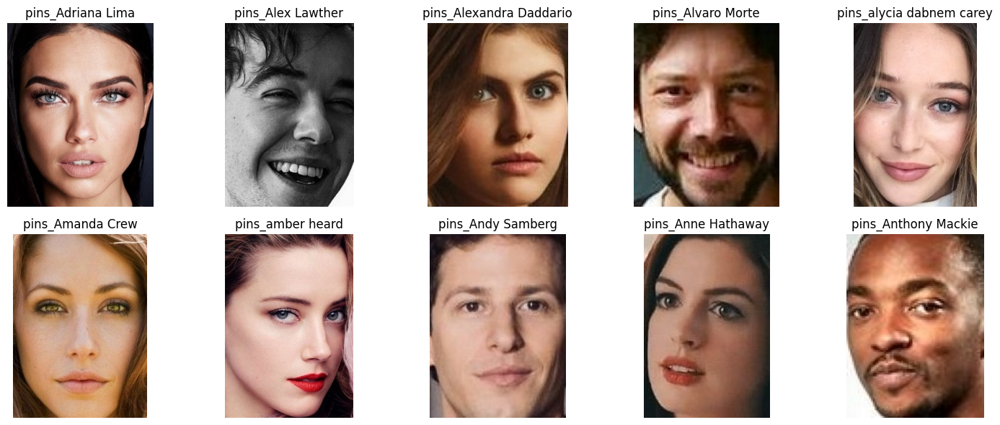

In [24]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

axes = axes.flatten()

for i, (persona, imagenes) in enumerate(personas_cumplen_ruta_con_una_imagen.items()):
    if i >= 10:
        break

    pil = cv2.cvtColor(cv2.imread(os.path.join(dataset_dir, persona, imagenes[0])), cv2.COLOR_BGR2RGB)
    pil = Image.fromarray(pil)

    boxes, probs, landmarks = detector.detect(pil, landmarks=True)

    if boxes is not None:
        for box, prob, landmark in zip(boxes, probs, landmarks):
            x1, y1, x2, y2 = box.astype(int)
            x1 = max(0, x1)
            y1 = max(0, y1)
            x2 = min(pil.width, x2)
            y2 = min(pil.height, y2)
            pil = pil.crop((x1, y1, x2, y2))
            bbox_ancho = x2 - x1
            print(f"Persona: {persona}, Probabilidad: {prob:.4f}, BBox: ({x1}, {y1}, {x2}, {y2}), Ancho: {bbox_ancho}")

    axes[i].imshow(pil)
    axes[i].set_title(persona)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [25]:
personas_cumplen_ruta_minimo = {}

for i, (persona, imagenes) in enumerate(personas_cumplen_ruta_con_una_imagen.items()):

    for img in imagenes:

        pil = cv2.cvtColor(cv2.imread(os.path.join(dataset_dir, persona, imagenes[0])), cv2.COLOR_BGR2RGB)
        pil = Image.fromarray(pil)

        if pil is None:
            print(f"No se pudo cargar: {ruta_imagen}")
            continue

        boxes, probs, landmarks = detector.detect(pil, landmarks=True)

        if boxes is not None:
            x1, y1, x2, y2 = boxes.astype(int)[0]
            # pil = pil.crop((x1, y1, x2, y2))

            x1 = max(0, x1)
            y1 = max(0, y1)
            x2 = min(pil.width, x2)
            y2 = min(pil.height, y2)

            bbox_ancho = x2 - x1
            bbox_alto = y2 - y1
            if bbox_ancho > 40 and bbox_alto > 40:
                personas_cumplen_ruta_minimo.setdefault(persona, []).append(
                    (img, boxes, probs, landmarks)
                )

In [26]:
total_imagenes_despues_minimo = sum(
    len(imagenes) for imagenes in personas_cumplen_ruta_minimo.values()
)

total_imagenes_antes_minimo = sum(
    len(imagenes) for imagenes in personas_cumplen_ruta_con_una_imagen.values()
)

if total_imagenes_despues_minimo < total_imagenes_antes_minimo:
    print(
        f"Se eliminaron {total_imagenes_antes_minimo - total_imagenes_despues_minimo} "
        "imágenes que no cumplen con el tamaño mínimo de 40x40 píxeles para el rostro."
    )

else:
    print("No se eliminaron imágenes; todas cumplen con el tamaño mínimo de 40x40 píxeles para el rostro.")

No se eliminaron imágenes; todas cumplen con el tamaño mínimo de 40x40 píxeles para el rostro.


Al quedarnos con las que contienen un minimo de 40x40 al detectar los rostros, hemos observado que cada una de las imagenes que tenemos cumplen con el minimo requerido.

## **Nitidez**

In [27]:
resultados = {}

for persona, imagenes in personas_cumplen_ruta_minimo.items():

    for i in range(len(imagenes)):
        gris = cv2.cvtColor(cv2.imread(os.path.join(dataset_dir, persona, imagenes[i][0])), cv2.COLOR_BGR2GRAY)

        nitidez = cv2.Laplacian(gris, cv2.CV_64F).var()

        if persona not in resultados:
            resultados[persona] = []

        resultados[persona].append({
            "imagen": str(os.path.join(dataset_dir, persona, imagenes[i][0])),
            "nitidez": nitidez
        })

In [28]:
adriana = resultados["pins_Adriana Lima"]

print("Resultados de nitidez para Adriana Lima:")

adriana_sorted = sorted(adriana, key=lambda x: x['nitidez'])

for dato in adriana_sorted:
    print(f"Imagen: {dato['imagen']}, Nitidez: {dato['nitidez']}")

Resultados de nitidez para Adriana Lima:
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima240_140.jpg, Nitidez: 15.007787563509044
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima172_73.jpg, Nitidez: 29.487041994660668
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima10_2.jpg, Nitidez: 40.54799407772943
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima126_28.jpg, Nitidez: 41.87881692427955
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima232_133.jpg, Nitidez: 46.94831378280484
Imagen: C:\Users\

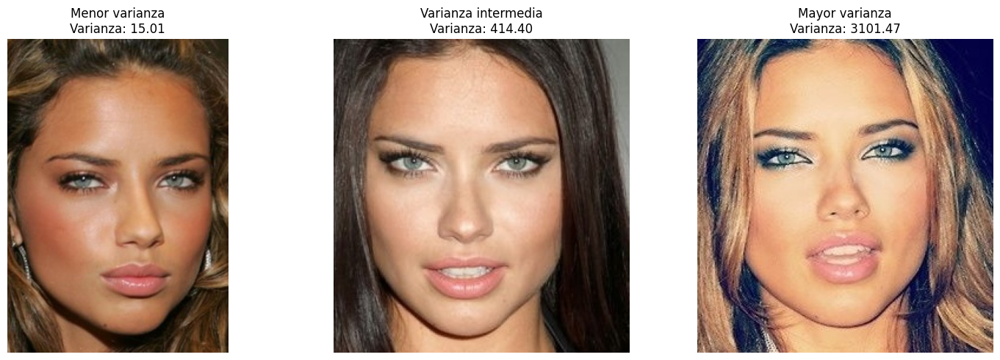

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

indices = [
    0,
    len(adriana_sorted) // 2,
    -1
]

titulos = [
    "Menor varianza",
    "Varianza intermedia",
    "Mayor varianza"
]

for ax, indice, titulo in zip(axes, indices, titulos):
    imagen = cv2.imread(adriana_sorted[indice]["imagen"])
    imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

    ax.imshow(imagen)
    ax.set_title(
        f"{titulo}\nVarianza: {adriana_sorted[indice]['nitidez']:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Luego de realizar la varianza de Laplaciano, a pesar de observar en el caso de Adriana, a pesar de que tiene un valor bajo de 15, la imagen no se ve borrosa ni se podría considerar mala para los entrenamientos.

In [30]:
print("Resultados de nitidez por persona:")

resultados_sorted = {persona: sorted(datos, key=lambda x: x['nitidez']) for persona, datos in resultados.items()}

for persona, datos in resultados_sorted.items():
    print(f"\nPersona: {persona}")
    for dato in datos:
        print(f"Imagen: {dato['imagen']}, Nitidez: {dato['nitidez']}")

Resultados de nitidez por persona:

Persona: pins_Adriana Lima
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima240_140.jpg, Nitidez: 15.007787563509044
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima172_73.jpg, Nitidez: 29.487041994660668
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima10_2.jpg, Nitidez: 40.54799407772943
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima126_28.jpg, Nitidez: 41.87881692427955
Imagen: C:\Users\grima\.cache\kagglehub\datasets\hereisburak\pins-face-recognition\versions\1\105_classes_pins_dataset\pins_Adriana Lima\Adriana Lima232_133.jpg, Nitidez: 46.9483137828

## **Imagenes duplicadas**

In [31]:
resultados = []

for persona, rutas in personas_cumplen_ruta_minimo.items():

    imagenes = {}

    for ruta in rutas:
        boxes, probs, landmarks = ruta[1], ruta[2], ruta[3]
        ruta = ruta[0]

        imagen = cv2.imread(os.path.join(dataset_dir, persona, ruta))

        if imagen is not None:
            imagenes[ruta] = (imagen, boxes, probs, landmarks)

    for (nombre1, img1), (nombre2, img2) in combinations(
        imagenes.items(), 2
    ):
        img1, boxes1, probs1, landmarks1 = img1
        img2, boxes2, probs2, landmarks2 = img2

        # Comparar imágenes del mismo tamaño
        if img1.shape != img2.shape:
            continue

        vector1 = img1.flatten().reshape(1, -1)
        vector2 = img2.flatten().reshape(1, -1)

        similitud = cosine_similarity(vector1, vector2)[0, 0]

        if similitud >= 0.95:  

            resultados.append({
                "persona": persona,
                "imagen_1": nombre1,
                "boxes_1": boxes1,
                "probs_1": probs1,
                "landmarks_1": landmarks1,
                "imagen_2": nombre2,
                "boxes_2": boxes2,
                "probs_2": probs2,
                "landmarks_2": landmarks2,
                "similitud_coseno": similitud
            })

Total de pares duplicados: 229
Pares que se muestran: 20
Personas distintas con duplicados: 70
{'persona': 'pins_Jason Momoa', 'imagen_1': 'Jason Momoa18_2464.jpg', 'boxes_1': array([[68.3033447265625, 58.85755157470703, 198.75775146484375,
        220.09866333007812]], dtype=object), 'probs_1': array([0.9999841451644897], dtype=object), 'landmarks_1': array([[[90.08662414550781, 119.89122009277344],
        [147.30099487304688, 113.78135681152344],
        [108.81350708007812, 149.91299438476562],
        [98.88633728027344, 183.26988220214844],
        [144.97808837890625, 180.64724731445312]]], dtype=object), 'imagen_2': 'Jason Momoa194_2477.jpg', 'boxes_2': array([[68.3033447265625, 58.85755157470703, 198.75775146484375,
        220.09866333007812]], dtype=object), 'probs_2': array([0.9999841451644897], dtype=object), 'landmarks_2': array([[[90.08662414550781, 119.89122009277344],
        [147.30099487304688, 113.78135681152344],
        [108.81350708007812, 149.91299438476562],
  

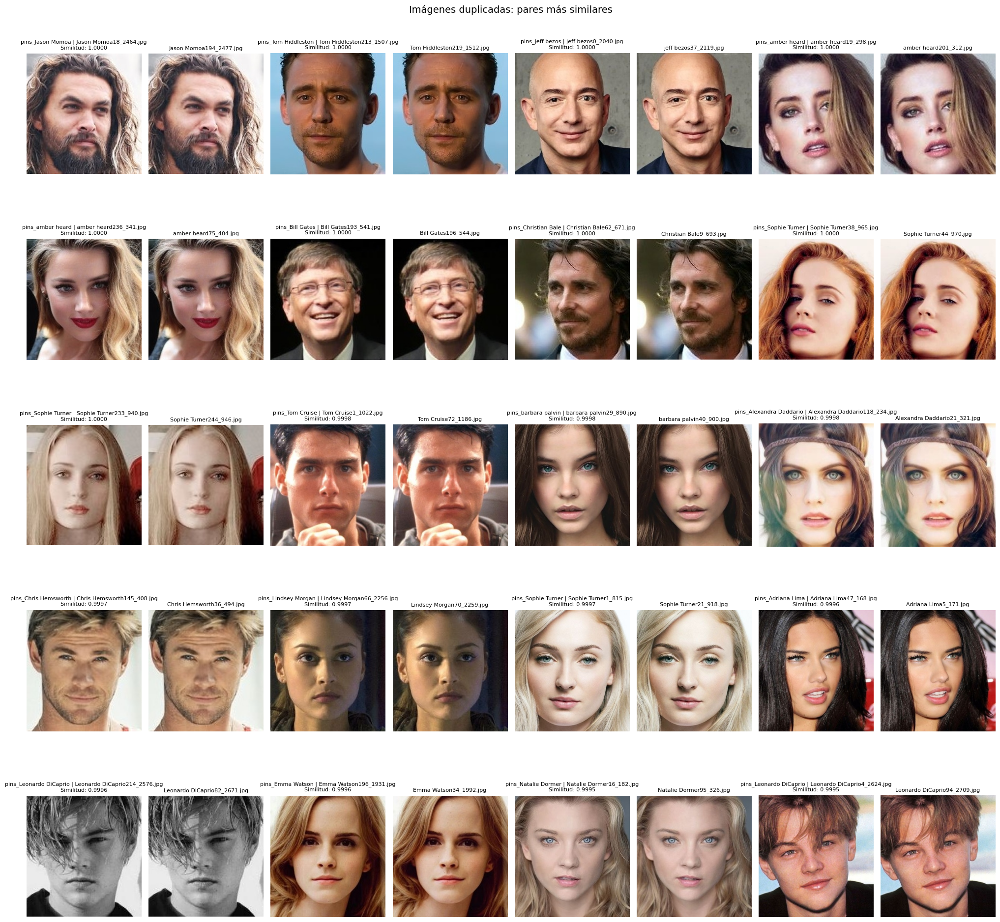

In [32]:
# Mostrar y visualizar los 20 pares más similares
resultados_ordenados = sorted(
    resultados,
    key=lambda x: x["similitud_coseno"],
    reverse=True
)

pares_a_mostrar = resultados_ordenados[:20]

print(f"Total de pares duplicados: {len(resultados_ordenados)}")
print(f"Pares que se muestran: {len(pares_a_mostrar)}")

personas_distintas = {resultado["persona"] for resultado in resultados_ordenados}
print(f"Personas distintas con duplicados: {len(personas_distintas)}")

cantidad_duplicados_por_persona = {}

for resultado in resultados_ordenados:
    persona = resultado["persona"]
    cantidad_duplicados_por_persona[persona] = (
        cantidad_duplicados_por_persona.get(persona, 0) + 1
    )

for resultado in pares_a_mostrar:
    print(resultado)

if pares_a_mostrar:
    pares_por_fila = 4
    cantidad_filas = (len(pares_a_mostrar) + pares_por_fila - 1) // pares_por_fila
    fig, axes = plt.subplots(
        cantidad_filas,
        pares_por_fila * 2,
        figsize=(20, 4 * cantidad_filas),
        squeeze=False
    )

    for indice, resultado in enumerate(pares_a_mostrar):
        fila, columna_par = divmod(indice, pares_por_fila)
        columna = columna_par * 2

        for eje, nombre_imagen in zip(
            axes[fila, columna:columna + 2],
            [resultado["imagen_1"], resultado["imagen_2"]]
        ):
            ruta_imagen = os.path.join(
                dataset_dir,
                resultado["persona"],
                nombre_imagen
            )
            imagen = cv2.imread(ruta_imagen)
            if imagen is None:
                raise FileNotFoundError(f"No se pudo leer la imagen: {ruta_imagen}")

            eje.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
            eje.set_title(nombre_imagen, fontsize=8)
            eje.axis("off")

        axes[fila, columna].set_title(
            f"{resultado['persona']} | {resultado['imagen_1']}\n"
            f"Similitud: {resultado['similitud_coseno']:.4f}",
            fontsize=8
        )

    for indice in range(len(pares_a_mostrar), cantidad_filas * pares_por_fila):
        fila, columna_par = divmod(indice, pares_por_fila)
        axes[fila, columna_par * 2].axis("off")
        axes[fila, columna_par * 2 + 1].axis("off")

    fig.suptitle("Imágenes duplicadas: pares más similares", fontsize=14)
    plt.tight_layout()
    plt.show()

Podemos observar que efectivamente son imágenes duplicadas debemos limpiar del dataset.

In [33]:
print("Cantidad de duplicados por persona:")
for persona, cantidad in cantidad_duplicados_por_persona.items():
    print(f"{persona}: {cantidad}")

Cantidad de duplicados por persona:
pins_Jason Momoa: 1
pins_Tom Hiddleston: 4
pins_jeff bezos: 1
pins_amber heard: 6
pins_Bill Gates: 2
pins_Christian Bale: 1
pins_Sophie Turner: 13
pins_Tom Cruise: 2
pins_barbara palvin: 3
pins_Alexandra Daddario: 4
pins_Chris Hemsworth: 3
pins_Lindsey Morgan: 1
pins_Adriana Lima: 3
pins_Leonardo DiCaprio: 6
pins_Emma Watson: 3
pins_Natalie Dormer: 13
pins_Amanda Crew: 2
pins_scarlett johansson: 3
pins_Elizabeth Lail: 6
pins_margot robbie: 17
pins_Nadia Hilker: 2
pins_Jennifer Lawrence: 14
pins_Katherine Langford: 3
pins_Richard Harmon: 1
pins_camila mendes: 1
pins_Zac Efron: 1
pins_Selena Gomez: 1
pins_Stephen Amell: 4
pins_Danielle Panabaker: 1
pins_alycia dabnem carey: 1
pins_Jake Mcdorman: 11
pins_Pedro Alonso: 3
pins_Irina Shayk: 3
pins_Chris Pratt: 2
pins_Millie Bobby Brown: 2
pins_grant gustin: 3
pins_Tom Holland: 4
pins_Maisie Williams: 1
pins_Robert De Niro: 1
pins_Shakira Isabel Mebarak: 9
pins_Mark Ruffalo: 1
pins_Taylor Swift: 1
pins_Inba

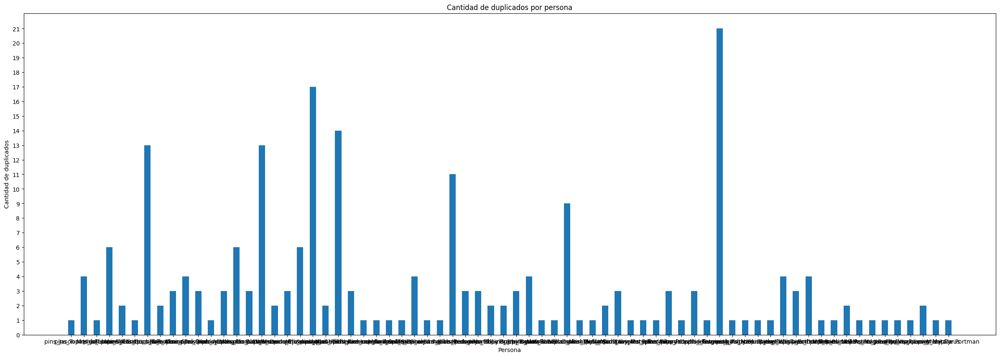

In [34]:
grafico_barra(
    list(cantidad_duplicados_por_persona.keys()),
    list(cantidad_duplicados_por_persona.values()),
    "Cantidad de duplicados por persona",
    "Persona",
    "Cantidad de duplicados",
    1
)

Hay al menos 231 imagenes supuestamente duplicadas, distribuidas entre 70 famosos distintos.

In [35]:
# Imágenes que se deben conservar: únicamente las imagen_1
imagenes_conservar = {}

for resultado in resultados_ordenados:
    persona = resultado["persona"]

    if persona not in imagenes_conservar:
        imagenes_conservar[persona] = set()

    imagenes_conservar[persona].add(resultado["imagen_1"])


# Crear una nueva versión sin las imágenes duplicadas (imagen_2)
personas_cumplen_ruta_sin_duplicados = {}

for persona, rutas in personas_cumplen_ruta_minimo.items():

    imagenes_a_conservar = imagenes_conservar.get(persona, set())

    imagenes_a_eliminar = {
        resultado["imagen_2"]
        for resultado in resultados_ordenados
        if resultado["persona"] == persona
        and resultado["imagen_2"] not in imagenes_a_conservar
    }

    personas_cumplen_ruta_sin_duplicados[persona] = [
        ruta
        for ruta in rutas
        if ruta[0] not in imagenes_a_eliminar
    ]

personas_cumplen_ruta_sin_duplicados

{'pins_Adriana Lima': [('Adriana Lima0_0.jpg',
   array([[19.684906005859375, -13.968206405639648, 572.3158569335938,
           681.6526489257812]], dtype=object),
   array([0.9918768405914307], dtype=object),
   array([[[169.5629119873047, 272.66668701171875],
           [441.7351379394531, 270.37109375],
           [309.97332763671875, 420.27557373046875],
           [212.09963989257812, 528.8135986328125],
           [406.54290771484375, 520.65283203125]]], dtype=object)),
  ('Adriana Lima101_3.jpg',
   array([[19.684906005859375, -13.968206405639648, 572.3158569335938,
           681.6526489257812]], dtype=object),
   array([0.9918768405914307], dtype=object),
   array([[[169.5629119873047, 272.66668701171875],
           [441.7351379394531, 270.37109375],
           [309.97332763671875, 420.27557373046875],
           [212.09963989257812, 528.8135986328125],
           [406.54290771484375, 520.65283203125]]], dtype=object)),
  ('Adriana Lima102_4.jpg',
   array([[19.6849060058593

# **Detección y alineación**

In [36]:
personas_alineadas = {}

for persona, registros in personas_cumplen_ruta_sin_duplicados.items():
    rostros_persona = []

    for registro in registros:
        nombre_imagen = registro[0]
        ruta_imagen = Path(dataset_dir) / persona / nombre_imagen
        imagen_bgr = cv2.imread(str(ruta_imagen))
        imagen = Image.fromarray(cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB))

        boxes, probs, landmarks = registro[1], registro[2], registro[3]

        x1, y1, x2, y2 = boxes.astype(int)[0]
        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(imagen.width, x2)
        y2 = min(imagen.height, y2)

        imagen_cropped = imagen.crop((x1, y1, x2, y2))

        cara_tensor_bush = detector(imagen)

        cara_alineada = cara_tensor_bush[0].permute(1, 2, 0).cpu().numpy()

        # cara_alineada = np.clip(
        #         (cara_alineada + 1) * 127.5,
        #         0,
        #         255
        #     ).astype(np.uint8)

        if persona not in personas_alineadas:
            personas_alineadas[persona] = []

        personas_alineadas[persona].append((imagen_cropped, cara_alineada, imagen))


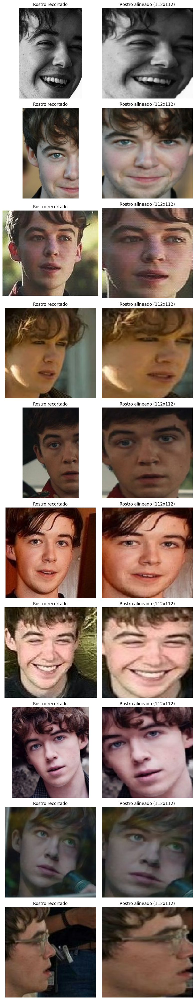

In [37]:
persona = "pins_Alex Lawther"
cantidad = 10

registros = personas_alineadas[persona][:cantidad]

fig, axes = plt.subplots(
    len(registros), 2,
    figsize=(8, 4 * len(registros)),
    squeeze=False
)

for i, registro in enumerate(registros):

    # Imagen recortada
    imagen_cropped = registro[0]
    axes[i, 0].imshow(imagen_cropped)
    axes[i, 0].set_title("Rostro recortado")

    # Imagen alineada, guardada previamente
    cara_alineada = registro[1]

    cara_alineada = np.clip(
        (cara_alineada + 1) * 127.5,
        0,
        255
    ).astype(np.uint8)

    axes[i, 1].imshow(cara_alineada)
    axes[i, 1].set_title("Rostro alineado (112x112)")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

# **Clustering exploratorio**

In [38]:
# Modelo de embeddings faciales
modelo = InceptionResnetV1(pretrained='vggface2').eval().to(device)
print(f"InceptionResnetV1 cargado | Embedding: 512 dimensiones")
print(f"Parámetros: {sum(p.numel() for p in modelo.parameters()) / 1e6:.1f}M")

InceptionResnetV1 cargado | Embedding: 512 dimensiones
Parámetros: 27.9M


In [42]:
# Extraer embeddings para todas las imágenes seleccionadas
# Pipeline: imagen → MTCNN (crop+align) → InceptionResnetV1 → embedding 512-d

embeddings = [] 
etiquetas = []
imagenes_ok = []  # guardamos las imágenes para visualizar después
    
i = 0

cantidad_imagenes = sum(len(registros) for registros in personas_alineadas.values())

print("Extrayendo embeddings...")
for persona, registros in personas_alineadas.items():
    rostros_persona = []
    nombre_persona = persona

    for registro in registros:
        pil = registro[2]  # Imagen original (RGB)
        cara = detector(pil)  # (N, 3, 160, 160) o None

        # Tomar la primera cara detectada
        if cara is None or len(cara) == 0:
            print(f"No se detectó rostro en la imagen de {nombre_persona}.")
            continue
        cara_input = cara[0].unsqueeze(0).to(device)  # (1, 3, 160, 160)

        with torch.no_grad():
            emb = modelo(cara_input)  # (1, 512), ya L2-normalizado

        embeddings.append(emb.cpu().squeeze().numpy())
        etiquetas.append(nombre_persona)
        imagenes_ok.append(pil)
        i += 1

        if (i + 1) % 20 == 0:
            print(f"  {i + 1}/{cantidad_imagenes} procesadas...")

embeddings = np.array(embeddings)
etiquetas = np.array(etiquetas)

print(f"\nEmbeddings extraídos: {len(embeddings)} de {cantidad_imagenes} imágenes")
print(f"Dimensión: {embeddings.shape[1]}")
print(f"Norma L2 promedio: {np.linalg.norm(embeddings, axis=1).mean():.4f} (debería ser ~1.0)")

Extrayendo embeddings...
  20/14518 procesadas...
  40/14518 procesadas...
  60/14518 procesadas...
  80/14518 procesadas...
  100/14518 procesadas...
  120/14518 procesadas...
  140/14518 procesadas...
  160/14518 procesadas...
  180/14518 procesadas...
  200/14518 procesadas...
  220/14518 procesadas...
  240/14518 procesadas...
  260/14518 procesadas...
  280/14518 procesadas...
  300/14518 procesadas...
  320/14518 procesadas...
  340/14518 procesadas...
  360/14518 procesadas...
  380/14518 procesadas...
  400/14518 procesadas...
  420/14518 procesadas...
  440/14518 procesadas...
  460/14518 procesadas...
  480/14518 procesadas...
  500/14518 procesadas...
  520/14518 procesadas...
  540/14518 procesadas...
  560/14518 procesadas...
  580/14518 procesadas...
  600/14518 procesadas...
  620/14518 procesadas...
  640/14518 procesadas...
  660/14518 procesadas...
  680/14518 procesadas...
  700/14518 procesadas...
  720/14518 procesadas...
  740/14518 procesadas...
  760/14518 proce

C:\Users\grima\AppData\Local\Temp\ipykernel_17444\1646577703.py:34: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


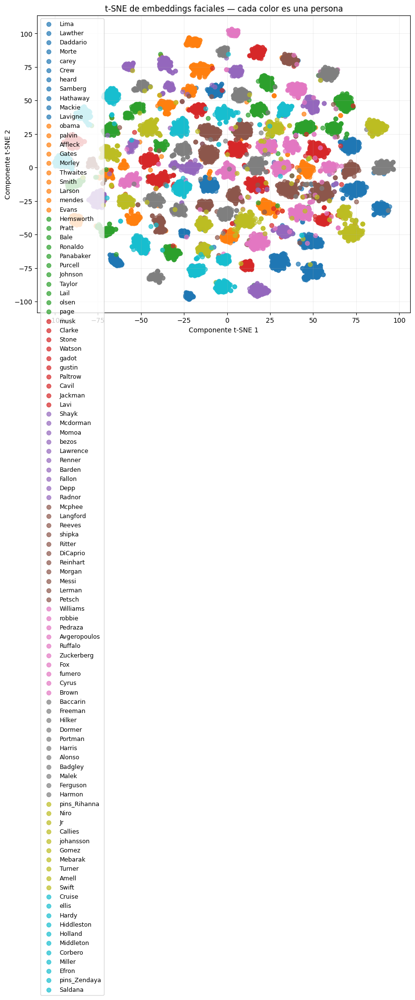

In [43]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=min(15, len(embeddings) - 1)
)

emb_2d = tsne.fit_transform(embeddings)

NOMBRES = personas_alineadas.keys()

fig, ax = plt.subplots(figsize=(10, 8))

colores = plt.cm.tab10(np.linspace(0, 1, len(NOMBRES)))

for persona_id, nombre in enumerate(NOMBRES):

    mask = etiquetas == nombre

    ax.scatter(
        emb_2d[mask, 0],
        emb_2d[mask, 1],
        label=nombre.split()[-1],
        s=40,
        alpha=0.7,
        color=colores[persona_id]
    )

ax.legend(fontsize=9, loc='best')
ax.set_title("t-SNE de embeddings faciales — cada color es una persona")
ax.set_xlabel("Componente t-SNE 1")
ax.set_ylabel("Componente t-SNE 2")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# **Balanceao del dataset**

Decidimos guiarnos con la persona que cuenta con menos cantidad de imagenes, para asi no tener que aumentar más imagenes.

In [45]:
minimas_imagenes_por_persona = min(len(registros) for registros in personas_alineadas.values())
print(f"Cantidad mínima de imágenes por persona después de todo el filtrado: {minimas_imagenes_por_persona}")

Cantidad mínima de imágenes por persona después de todo el filtrado: 63


In [46]:
for persona, registros in personas_alineadas.items():
    if len(registros) > minimas_imagenes_por_persona:
        personas_alineadas[persona] = registros[:minimas_imagenes_por_persona]

In [51]:
ruta_guardado = Path.cwd()
print(f"Guardando dataset final en: {ruta_guardado}")

Guardando dataset final en: c:\Users\grima\Desktop\UNR\TUIA\5° cuatri\COMPUTER VISION\PRACTICA\tuia-face-recognition-app


In [52]:
for persona, registros in personas_alineadas.items():

    nombre_persona = persona.split("_")[-1]

    carpetas_persona = ruta_guardado / "dataset" / nombre_persona
    carpetas_persona.mkdir(parents=True, exist_ok=True)

    # Subcarpetas para imágenes alineadas y originales
    carpeta_alineadas = carpetas_persona / "alineadas"
    carpeta_recortadas = carpetas_persona / "recortadas"
    carpeta_originales = carpetas_persona / "originales"
    carpeta_alineadas.mkdir(parents=True, exist_ok=True)
    carpeta_recortadas.mkdir(parents=True, exist_ok=True)
    carpeta_originales.mkdir(parents=True, exist_ok=True)

    for i, registro in enumerate(registros):
        imagen_cropped = registro[0]
        cara_alineada = registro[1]
        imagen_original = registro[2]

        # Guardar imagen recortada
        ruta_recortada = carpeta_recortadas / f"{nombre_persona}_{i + 1:03d}.jpg"
        imagen_cropped.save(ruta_recortada)

        # Guardar imagen alineada
        cara_alineada_uint8 = np.clip((cara_alineada + 1) * 127.5, 0, 255).astype(np.uint8)
        ruta_alineada = carpeta_alineadas / f"{nombre_persona}_{i + 1:03d}.jpg"
        Image.fromarray(cara_alineada_uint8).save(ruta_alineada)

        # Guardar imagen original
        ruta_original = carpeta_originales / f"{nombre_persona}_{i + 1:03d}.jpg"
        imagen_original.save(ruta_original)

print("Guardado completado. Estructura de carpetas:")
for persona in personas_alineadas.keys():
    nombre_persona = persona.split("_")[-1]
    print(f"- {nombre_persona}/")
    print(f"  - alineadas/")
    print(f"  - recortadas/")
    print(f"  - originales/")

Guardado completado. Estructura de carpetas:
- Adriana Lima/
  - alineadas/
  - recortadas/
  - originales/
- Alex Lawther/
  - alineadas/
  - recortadas/
  - originales/
- Alexandra Daddario/
  - alineadas/
  - recortadas/
  - originales/
- Alvaro Morte/
  - alineadas/
  - recortadas/
  - originales/
- alycia dabnem carey/
  - alineadas/
  - recortadas/
  - originales/
- Amanda Crew/
  - alineadas/
  - recortadas/
  - originales/
- amber heard/
  - alineadas/
  - recortadas/
  - originales/
- Andy Samberg/
  - alineadas/
  - recortadas/
  - originales/
- Anne Hathaway/
  - alineadas/
  - recortadas/
  - originales/
- Anthony Mackie/
  - alineadas/
  - recortadas/
  - originales/
- Avril Lavigne/
  - alineadas/
  - recortadas/
  - originales/
- barack obama/
  - alineadas/
  - recortadas/
  - originales/
- barbara palvin/
  - alineadas/
  - recortadas/
  - originales/
- Ben Affleck/
  - alineadas/
  - recortadas/
  - originales/
- Bill Gates/
  - alineadas/
  - recortadas/
  - original